# Oxford Pets mit shapiq: Vorhersagen und regionale Interaktionen

- Wir erklären den **bereits trainierten VGG-Klassifikator**, ohne ihn neu zu trainieren.
- Eine feste Kohorte enthält **ein Testbild je Rasse**. Alle 37 Bilder werden ausgewertet;
  drei diagnostische Fälle helfen beim Lesen der Ergebnisse.
- Neun Rasterregionen bilden ein kooperatives Spiel. Für jede der 512 möglichen
  Koalitionen messen wir die Wahrscheinlichkeit derselben, vorher festgelegten Zielklasse.
- Wir untersuchen Shapley-Werte, Interaktionen, Tier/Hintergrund, zwei
  Maskierungsreferenzen, Approximationsbudgets und kontrastive Rassenentscheidungen.
- **Dieses Notebook verwendet shapiq allein.** Der exportierte Merkmalscache macht die
  spätere Kombination mit den mehreren Klassifikationsköpfen günstig.


## 1. Vorhandene Baseline laden

- Voraussetzung ist das ausgeführte Baseline-Notebook `dan_02-0_...` mit gespeichertem Kopf,
  Merkmalen und Vorhersagen. Der gemeinsame Helfer prüft diese Artefakte.
- Die Kohorte kommt aus derselben gespeicherten Auswahl wie in den Nachbar-Notebooks.
- VGG wird eingefroren geladen. Bei maskierten Bildern werden nur fehlende Merkmale neu
  berechnet; ein erneuter Lauf verwendet passende Caches.
- Die erste vollständige Rasteranalyse benötigt 37 × 2 × 512 = **37.888 maskierte
  Bildvorhersagen**, dazu kleine Kontroll- und Diagnoseanalysen. Die Rastermerkmale
  belegen ungefähr **592 MiB**. Installationen erfolgen außerhalb des Notebooks.
- **SLIC-Abhängigkeit:** zusätzlich `scikit-image`; die geprüfte Umgebung verwendet **0.26.0**. Der Start prüft die Verfügbarkeit vor der langen Merkmalsextraktion und zeigt die installierte Version. Installationen erfolgen außerhalb des Notebooks; ein Installationshinweis nennt den Befehl für den Repository-Root.


In [1]:
from __future__ import annotations

import hashlib
import json
import sys
import time
from importlib.metadata import version as distribution_version
from importlib.util import find_spec
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapiq
import torch
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm
from shapiq.plot import si_graph_plot, waterfall_plot
from shapiq_games import ImageClassifier
from shapiq_games.vision import get_superpixels, grid_regions

# Check the optional SLIC dependency before loading VGG or extracting any cohort features.
if find_spec("skimage") is None:
    raise ModuleNotFoundError(
        "Für die SLIC-Analyse fehlt scikit-image. Installation außerhalb des Notebooks "
        "aus dem Repository-Root: "
        "uv pip install --python .venv/bin/python scikit-image==0.26.0"
    )
SCIKIT_IMAGE_VERSION = distribution_version("scikit-image")
print("SLIC-Abhängigkeit: scikit-image", SCIKIT_IMAGE_VERSION)

NOTEBOOK_DIR = next(
    directory / "experiments" / "group-d_experiments"
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src" / "probly").is_dir()
)
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from dan_02_common import (
    ARTIFACT_DIR,
    DATA_ROOT,
    REPO_ROOT,
    diagnostic_cases,
    extract_crops,
    head_logits,
    load_backbone,
    load_baseline,
    load_crop,
    load_selection,
    load_torch,
    load_trimap,
    make_head,
    save_torch,
    select_device,
    state_fingerprint,
    versions,
)

SEED = 0
FILLS = ("blur", "mean")
EXTRACTION_BATCH_SIZE = 4
APPROXIMATION_BUDGETS = (64, 128, 256, 512)
APPROXIMATION_SEEDS = (0, 1, 2)
SHAPIQ_DIR = ARTIFACT_DIR / "shapiq"
SHAPIQ_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_DIR = SHAPIQ_DIR / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

bundle = load_baseline()
checkpoint = bundle["checkpoint"]
selection = load_selection()
classes = list(checkpoint["classes"])
baseline_predictions = bundle["baseline_predictions"]
BASELINE_FINGERPRINT = state_fingerprint(checkpoint["head_state_dict"])
DEVICE = select_device()
head = make_head(
    checkpoint["config"], len(classes),
    state_dict=checkpoint["head_state_dict"], device="cpu",
).eval()
backbone = load_backbone(device=DEVICE)
VERSIONS = versions()
cohort_indices = list(map(int, selection["explanation_indices"]))
cohort_ids = list(selection["explanation_ids"])
cases = diagnostic_cases(bundle, selection)
assert len(cohort_indices) == len(cohort_ids) == 37
assert len(set(cohort_ids)) == 37
assert set(baseline_predictions["labels"][cohort_indices].tolist()) == set(range(37))
assert [baseline_predictions["image_ids"][i] for i in cohort_indices] == cohort_ids
assert baseline_predictions["baseline_fingerprint"] == BASELINE_FINGERPRINT
print("Gerät für VGG:", DEVICE, "| shapiq:", VERSIONS.get("shapiq", "unbekannt"))
print("Kohorte:", len(cohort_ids), "Bilder, ein Bild je Rasse")
display(pd.DataFrame(cases))


SLIC-Abhängigkeit: scikit-image 0.26.0


Gerät für VGG: mps | shapiq: 1.8.0
Kohorte: 37 Bilder, ein Bild je Rasse


,role,index,image_id,target_class,true_class,comparison_class,confidence
0,Sicher richtig,3067,scottish_terrier_89,30,30,36,1.000000
1,Unsicher richtig,977,British_Shorthair_93,9,9,7,0.661356
2,Sicher falsch,3319,Sphynx_30,0,33,33,0.782927


## 2. Spielregeln und ein gemeinsamer Merkmalscache

- **Spieler:** neun feste Regionen des tatsächlichen 224 × 224-Modellinputs.
- **Ziel:** die Baseline-Vorhersage des unveränderten Bildes. Die Klasse wechselt beim
  Maskieren nicht. Bei Fehlern betrachten wir zusätzlich die tatsächliche Rasse.
- **Referenz `blur`:** die von shapiq erzeugte unscharfe Kopie; sie enthält weiterhin
  grobe Bildinformation. **Referenz `mean`:** die mittlere RGB-Farbe dieses Bildausschnitts,
  nicht die ImageNet-Normalisierungskonstante.
- `ImageClassifier.masked_image` übernimmt die Maskierung. Ein gespeicherter
  Koalitions-Score-Callable ist die ebenfalls von shapiq unterstützte Schnittstelle zur
  exakten Rechnung. Eine eigene Game-Klasse ist nicht nötig.
- Wir berechnen VGG-Merkmale pro maskiertem Bild einmal und leiten daraus alle 37 Logits
  ab. Die Initialisierung eines neuen `ImageClassifier` benötigt zusätzlich drei kleine
  Modellkontrollen; eine zweite vollständige Auswertung mit `precompute()` entfällt.
- Merkmalsidentität und Kopfidentität sind getrennt: Ein neuer Kopf kann dieselben
  Bildmerkmale verwenden. Caches enthalten keine NumPy-Objekte im Torch-Pickle.


In [2]:
CNN_IMAGE_EVALUATIONS = 0

def tensor_digest(values: torch.Tensor | np.ndarray) -> str:
    """Return a stable digest of a tensor's dtype, shape, and contiguous bytes."""
    array = values.detach().cpu().numpy() if isinstance(values, torch.Tensor) else np.asarray(values)
    digest = hashlib.sha256()
    digest.update(str(array.dtype).encode())
    digest.update(str(array.shape).encode())
    digest.update(np.ascontiguousarray(array).tobytes())
    return digest.hexdigest()


def predict_cropped_rgb(images: np.ndarray) -> np.ndarray:
    """Predict already cropped RGB images without repeating spatial preprocessing."""
    global CNN_IMAGE_EVALUATIONS
    CNN_IMAGE_EVALUATIONS += len(images)
    features = extract_crops(backbone, images, batch_size=EXTRACTION_BATCH_SIZE)
    return head_logits(head, features).softmax(1).numpy()


def make_image_game(crop: np.ndarray, regions: np.ndarray, fill: str, target: int) -> ImageClassifier:
    """Construct the public image game with a fixed class and built-in reference."""
    return ImageClassifier(
        crop, model=predict_cropped_rgb, regions=regions, fill=fill,
        class_index=target, normalize=False, batch_size=EXTRACTION_BATCH_SIZE,
    )


def binary_coalitions(n_players: int) -> np.ndarray:
    """Enumerate coalitions in binary order, with player zero as the lowest bit."""
    codes = np.arange(2**n_players, dtype=np.int64)
    return ((codes[:, None] >> np.arange(n_players)) & 1).astype(bool)


def coalition_codes(coalitions: np.ndarray, n_players: int) -> np.ndarray:
    """Map a Boolean coalition matrix to its dense binary table rows."""
    coalitions = np.atleast_2d(coalitions)
    if coalitions.shape[1] != n_players or not np.isin(coalitions, (0, 1)).all():
        raise ValueError("Expected a binary coalition matrix with the documented player count.")
    return coalitions.astype(np.int64) @ (1 << np.arange(n_players))


def score_callable(scores: np.ndarray, n_players: int):
    """Return a scalar game that only looks up precomputed coalition values."""
    scores = np.asarray(scores, dtype=np.float64)
    if scores.shape != (2**n_players,) or not np.isfinite(scores).all():
        raise ValueError("Expected one finite scalar per coalition.")
    def game(coalitions: np.ndarray) -> np.ndarray:
        return scores[coalition_codes(coalitions, n_players)]
    return game


def exact_values(scores: np.ndarray, n_players: int):
    """Compute SV and order-two k-SII from one in-memory score table."""
    exact = shapiq.ExactComputer(score_callable(scores, n_players), n_players=n_players)
    sv = exact(index="SV", order=1)
    ksii = exact(index="k-SII", order=min(2, n_players))
    singles = np.array([sv[(i,)] for i in range(n_players)], dtype=np.float64)
    ksii_single = np.array([ksii[(i,)] for i in range(n_players)], dtype=np.float64)
    pairs = np.zeros((n_players, n_players), dtype=np.float64)
    for i in range(n_players):
        for j in range(i + 1, n_players):
            pairs[i, j] = pairs[j, i] = ksii[(i, j)]
    np.testing.assert_allclose(sv.baseline_value + singles.sum(), scores[-1], atol=1e-6)
    np.testing.assert_allclose(
        ksii.baseline_value + ksii_single.sum() + np.triu(pairs, 1).sum(),
        scores[-1], atol=1e-6,
    )
    return sv, ksii, singles, ksii_single, pairs


def feature_spec(image_id, test_index, crop, trimap, regions, kind, fill, semantic_labels):
    """Describe feature identity independently from any classifier head."""
    return {
        "schema_version": 1,
        "image_id": image_id,
        "test_index": int(test_index),
        "split": "test",
        "regions_kind": kind,
        "fill": fill,
        "semantic_labels": list(map(int, semantic_labels)),
        "crop_digest": tensor_digest(crop),
        "trimap_digest": tensor_digest(trimap),
        "regions_digest": tensor_digest(regions.astype(np.int64)),
        "weights": checkpoint["weights"],
        "preprocessing": checkpoint["preprocessing"],
        "feature_dim": int(checkpoint["config"]["feature_dim"]),
        "dtype": "float32",
        "coalition_order": "binary; player zero is lowest bit",
        "mask_implementation": "shapiq_games.ImageClassifier.masked_image",
        "versions": {name: VERSIONS.get(name) for name in ("torch", "torchvision", "Pillow", "shapiq", "scikit-image")},
    }


def load_record(record: dict) -> dict:
    """Load one exported record using the common safe Torch reader."""
    return load_torch(ARTIFACT_DIR / record["path"], prerequisite="Run the shapiq feature cells first.")


def build_record(image_id, test_index, crop, trimap, regions, kind, fill, semantic_labels=()):
    """Load or extract one finite coalition table, then refresh its head-dependent scores."""
    global CNN_IMAGE_EVALUATIONS
    target = int(baseline_predictions["probabilities"][test_index].argmax())
    true_class = int(baseline_predictions["labels"][test_index])
    regions = np.asarray(regions, dtype=np.int64)
    n_players = int(regions.max()) + 1
    assert np.array_equal(np.unique(regions), np.arange(n_players))
    assert regions.shape == crop.shape[:2] == trimap.shape
    coalitions = binary_coalitions(n_players)
    spec = feature_spec(image_id, test_index, crop, trimap, regions, kind, fill, semantic_labels)
    path = FEATURE_DIR / f"{image_id}__{kind}__{fill}.pt"
    features = None
    if path.exists():
        try:
            cached = load_torch(path)
            if cached["manifest"]["feature"] == spec:
                features = cached["features"]
                assert features.dtype == torch.float32
                assert features.shape == (len(coalitions), checkpoint["config"]["feature_dim"])
                assert torch.isfinite(features).all()
                assert torch.equal(cached["coalitions"], torch.from_numpy(coalitions))
        except (OSError, RuntimeError, ValueError, KeyError, TypeError, AssertionError, EOFError) as error:
            print(f"Cache neu berechnen: {path.name}: {error}")
            features = None
    image_game = None
    if features is None:
        image_game = make_image_game(crop, regions, fill, target)
        start = time.perf_counter()
        features = extract_crops(
            backbone, (image_game.masked_image(coalition) for coalition in coalitions),
            batch_size=EXTRACTION_BATCH_SIZE,
        ).float().cpu()
        CNN_IMAGE_EVALUATIONS += len(coalitions)
        print(f"  {kind}/{fill}: {len(coalitions)} Koalitionen, {time.perf_counter() - start:.1f} s")
    torch.testing.assert_close(
        features[-1], bundle["test"]["features"][test_index], rtol=1e-4, atol=1e-4,
    )
    logits = head_logits(head, features).float().cpu()
    probabilities = logits.softmax(1)
    torch.testing.assert_close(
        probabilities[-1], baseline_predictions["probabilities"][test_index], rtol=1e-4, atol=1e-5,
    )
    scores = probabilities[:, target].numpy().astype(np.float64)
    if image_game is not None:
        np.testing.assert_allclose(scores[[0, -1]], [image_game.empty_value, image_game.original_model_output], atol=1e-5)
    sv, ksii, singles, ksii_single, pairs = exact_values(scores, n_players)
    payload = {
        "manifest": {
            "feature": spec,
            "scores": {"baseline_fingerprint": BASELINE_FINGERPRINT, "target_class": target, "shapiq_version": VERSIONS.get("shapiq")},
        },
        "image_id": image_id,
        "test_index": int(test_index),
        "target_class": target,
        "true_class": true_class,
        "crop": torch.from_numpy(np.array(crop, copy=True)).to(torch.uint8),
        "trimap": torch.from_numpy(np.array(trimap, copy=True)).long(),
        "regions": torch.from_numpy(regions.copy()).long(),
        "coalitions": torch.from_numpy(coalitions),
        "features": features,
        "baseline_logits": logits,
        "baseline_scores": torch.from_numpy(scores.copy()).float(),
        "sv": torch.from_numpy(singles.copy()).float(),
        "ksii_single": torch.from_numpy(ksii_single.copy()).float(),
        "ksii_pairs": torch.from_numpy(pairs.copy()).float(),
        "sv_baseline": float(sv.baseline_value),
        "ksii_baseline": float(ksii.baseline_value),
    }
    save_torch(path, payload)
    return {
        "image_id": image_id, "test_index": int(test_index),
        "target_class": target, "true_class": true_class,
        "regions_kind": kind, "fill": fill,
        "path": path.relative_to(ARTIFACT_DIR).as_posix(),
        "n_players": n_players,
        "semantic_labels": list(map(int, semantic_labels)),
        "absent_semantic_labels": [label for label in (1, 2, 3) if label not in semantic_labels] if kind == "semantic" else [],
    }


## 3. Alle 37 Bilder: Raster und semantische Regionen

- Das Raster bleibt für alle Bilder gleich. Seine vollständige Auswertung ist unsere
  Referenz für die spätere Approximation.
- Das semantische Spiel verwendet **Tier, Hintergrund und unklassifizierten Bereich** als
  getrennte Spieler. Sind alle vorhanden, gibt es nur acht Koalitionen.
- Fehlende Trimap-Kategorien erzeugen keinen leeren Spieler. Die tatsächlich vorhandenen
  Labels und fehlenden Kategorien stehen im Export und werden unten berichtet.
- Nach jedem fertigen Eintrag wird der Index aktualisiert. Ein unterbrochener Lauf kann
  auf den validierten Merkmalen fortsetzen. Der abschließende Index markiert Vollständigkeit.


In [3]:
records = []
index_payload = {
    "schema_version": 1, "baseline_fingerprint": BASELINE_FINGERPRINT,
    "cohort_ids": cohort_ids, "diagnostic_cases": cases,
    "records": records, "complete": False,
}

def write_index(complete: bool = False) -> None:
    """Publish progress after each atomically saved feature table."""
    index_payload["complete"] = complete
    temporary = SHAPIQ_DIR / "index.tmp.json"
    temporary.write_text(json.dumps(index_payload, indent=2, ensure_ascii=False), encoding="utf-8")
    temporary.replace(SHAPIQ_DIR / "index.json")


start = time.perf_counter()
for position, (test_index, image_id) in enumerate(zip(cohort_indices, cohort_ids, strict=True), start=1):
    crop = load_crop(image_id)
    trimap = load_trimap(image_id)
    assert set(np.unique(trimap)).issubset({1, 2, 3})
    labels_present = np.unique(trimap).astype(int).tolist()
    semantic_regions = np.searchsorted(labels_present, trimap).astype(np.int64)
    print(f"{position:02d}/37: {image_id} ({classes[int(baseline_predictions['labels'][test_index])]})")
    for kind, regions, semantic_labels in (
        ("grid", grid_regions(224, 224, 3, 3), ()),
        ("semantic", semantic_regions, labels_present),
    ):
        for fill in FILLS:
            records.append(build_record(
                image_id, test_index, crop, trimap, regions, kind, fill, semantic_labels,
            ))
            write_index()
print(f"Raster und semantische Spiele fertig: {(time.perf_counter() - start) / 60:.1f} min")
print("In diesem Lauf bisher durch VGG ausgewertete Bilder:", CNN_IMAGE_EVALUATIONS)


01/37: Abyssinian_79 (Abyssinian)


02/37: american_bulldog_208 (American Bulldog)
03/37: american_pit_bull_terrier_42 (American Pit Bull Terrier)


04/37: basset_hound_66 (Basset Hound)
05/37: beagle_38 (Beagle)


06/37: Bengal_196 (Bengal)
07/37: Birman_99 (Birman)


08/37: Bombay_214 (Bombay)
09/37: boxer_39 (Boxer)


10/37: British_Shorthair_93 (British Shorthair)
11/37: chihuahua_21 (Chihuahua)


... (10 outputs left out)

32/37: shiba_inu_91 (Shiba Inu)
33/37: Siamese_59 (Siamese)


34/37: Sphynx_30 (Sphynx)
35/37: staffordshire_bull_terrier_33 (Staffordshire Bull Terrier)


36/37: wheaten_terrier_23 (Wheaten Terrier)
37/37: yorkshire_terrier_31 (Yorkshire Terrier)


Raster und semantische Spiele fertig: 0.1 min
In diesem Lauf bisher durch VGG ausgewertete Bilder: 0


## 4. Drei Fallstudien zusätzlich mit Superpixeln

- SLIC passt die Regionen an die Bildstruktur an. Wir fordern ungefähr neun Superpixel an;
  die tatsächliche Spielerzahl wird geprüft und exportiert.
- Beide Referenzen bleiben gleich definiert. Auch diese kleinen Spiele berechnen wir exakt.
- Rasterkoeffizienten und Superpixelkoeffizienten gehören zu unterschiedlichen Spielern.
  Ein direkter Koeffizientenvergleich zwischen ihnen wäre deshalb irreführend.


In [4]:
seen_case_ids = set()
for case in cases:
    image_id = case["image_id"]
    if image_id in seen_case_ids:
        continue
    seen_case_ids.add(image_id)
    crop, trimap = load_crop(image_id), load_trimap(image_id)
    regions = get_superpixels(crop, n_segments=9).astype(np.int64) - 1
    assert 1 <= len(np.unique(regions)) <= 9
    for fill in FILLS:
        records.append(build_record(image_id, int(case["index"]), crop, trimap, regions, "slic", fill))
        write_index()
write_index(complete=True)
assert len([r for r in records if r["regions_kind"] == "grid"]) == 74
assert len([r for r in records if r["regions_kind"] == "semantic"]) == 74
print("Vollständiger Export:", SHAPIQ_DIR / "index.json")
print("VGG-Bildauswertungen dieses Laufs:", CNN_IMAGE_EVALUATIONS)
print("Fehlende semantische Kategorien:")
display(pd.DataFrame([
    {"image_id": record["image_id"], "fehlende_Labels": record["absent_semantic_labels"]}
    for record in records
    if record["regions_kind"] == "semantic" and record["fill"] == "blur" and record["absent_semantic_labels"]
]))


Vollständiger Export: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/shapiq/index.json
VGG-Bildauswertungen dieses Laufs: 0
Fehlende semantische Kategorien:


""


## 5. Was wird erklärt? Erst die Referenz, dann die Beiträge

- Eine positive SV erhöht die Wahrscheinlichkeit der festgehaltenen Zielklasse relativ zur
  Referenz; eine negative senkt sie. Zusammen mit dem Referenzwert ergeben alle SV den Vollbildwert.
- Alle Raster-Fälle und beide Referenzen teilen denselben symmetrischen Farbbereich.
  Die Superpixelabbildung verwendet ebenfalls einen gemeinsamen Bereich über alle Fälle
  und beide Referenzen. So sind sowohl Fall- als auch Referenzunterschiede vergleichbar.
- Auf dem Raster ist die Farbe ein **Regionsbeitrag**, keine separat gemessene Pixelrelevanz.


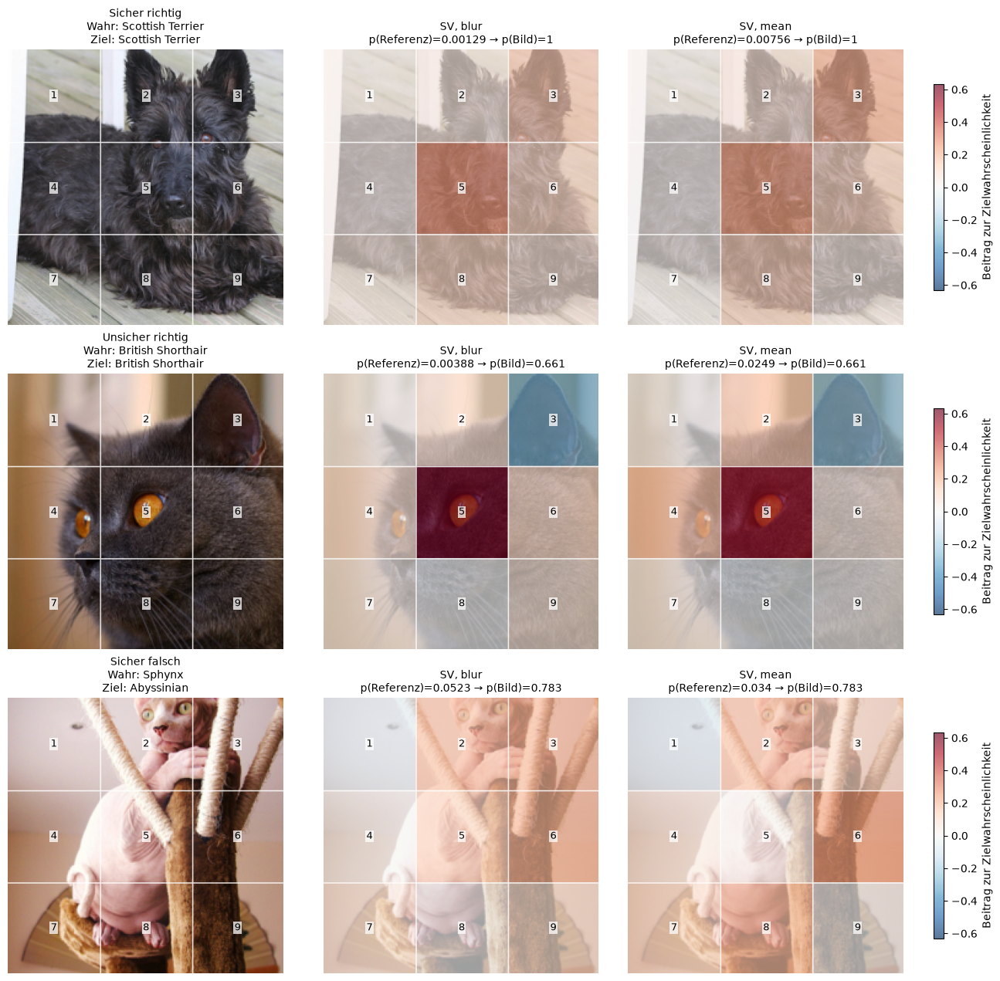

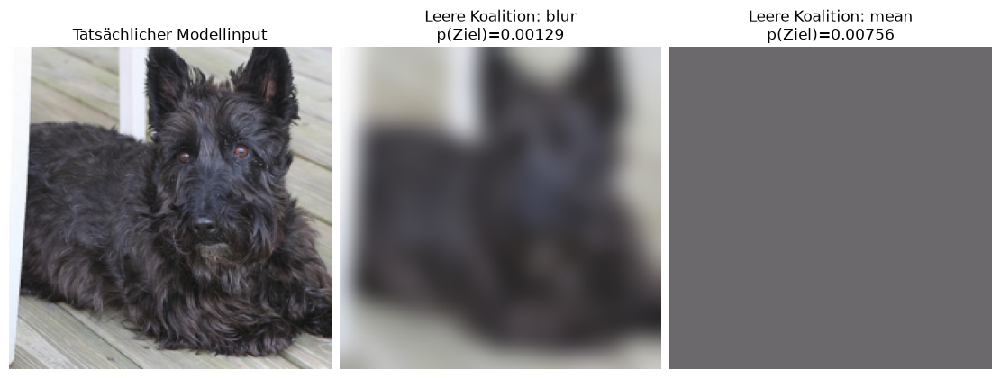

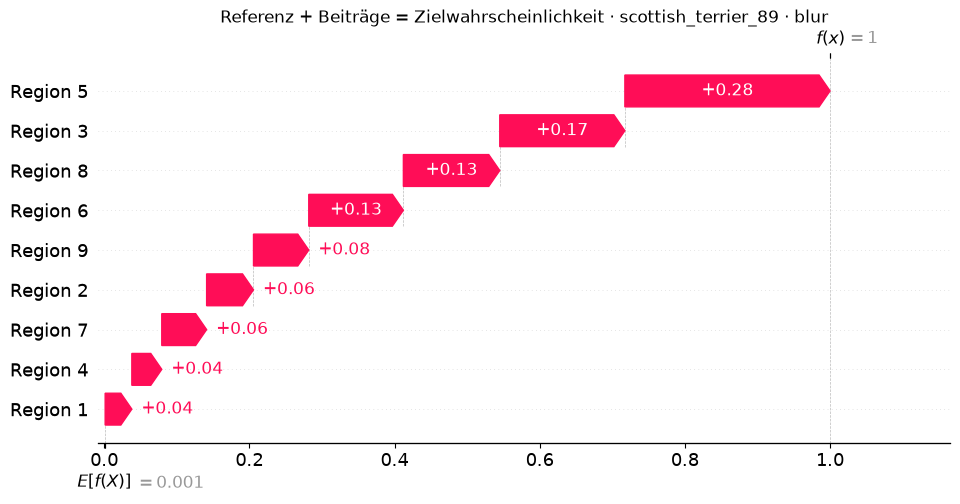

In [5]:
def find_record(image_id: str, kind: str = "grid", fill: str = "blur") -> dict:
    """Find an exported image/region/reference record without relying on list order."""
    return next(r for r in records if r["image_id"] == image_id and r["regions_kind"] == kind and r["fill"] == fill)


def image_explanations(payload: dict, scores: np.ndarray | None = None):
    """Reconstruct library explanation objects cheaply from a saved scalar table."""
    if scores is None:
        scores = payload["baseline_scores"].double().numpy()
    return exact_values(scores, payload["coalitions"].shape[1])[:2]


def region_map(payload: dict, values: np.ndarray) -> np.ndarray:
    """Broadcast regional contributions to the displayed pixels."""
    return np.asarray(values)[payload["regions"].numpy()]


def show_region_boundaries(ax, payload: dict) -> None:
    """Mark the actual region boundaries and their one-based display labels."""
    regions = payload["regions"].numpy()
    boundary = np.zeros_like(regions, dtype=bool)
    boundary[1:] |= regions[1:] != regions[:-1]
    boundary[:, 1:] |= regions[:, 1:] != regions[:, :-1]
    boundary_rgba = np.zeros((*regions.shape, 4), dtype=float)
    boundary_rgba[boundary] = (1, 1, 1, 0.85)
    ax.imshow(boundary_rgba)
    for player in range(payload["coalitions"].shape[1]):
        yy, xx = np.where(regions == player)
        ax.text(float(xx.mean()), float(yy.mean()), str(player + 1), ha="center", va="center",
                fontsize=9, color="black", bbox={"facecolor": "white", "alpha": 0.75, "edgecolor": "none", "pad": 1})


if cases:
    grid_limit = max(
        float(load_record(find_record(case["image_id"], fill=fill))["sv"].abs().max())
        for case in cases for fill in FILLS
    )
    grid_norm = TwoSlopeNorm(vmin=-max(grid_limit, 1e-8), vcenter=0, vmax=max(grid_limit, 1e-8))
    fig, axes = plt.subplots(len(cases), 3, figsize=(13, 4.2 * len(cases)), squeeze=False, layout="constrained")
    for row, case in enumerate(cases):
        payloads = [load_record(find_record(case["image_id"], fill=fill)) for fill in FILLS]
        norm = grid_norm
        first = payloads[0]
        axes[row, 0].imshow(first["crop"].numpy())
        show_region_boundaries(axes[row, 0], first)
        axes[row, 0].set_title(f"{case['role']}\nWahr: {classes[first['true_class']]}\nZiel: {classes[first['target_class']]}", fontsize=10)
        for col, (fill, payload) in enumerate(zip(FILLS, payloads, strict=True), start=1):
            axes[row, col].imshow(payload["crop"].numpy())
            heat = axes[row, col].imshow(region_map(payload, payload["sv"].numpy()), cmap="RdBu_r", norm=norm, alpha=0.65)
            show_region_boundaries(axes[row, col], payload)
            axes[row, col].set_title(f"SV, {fill}\np(Referenz)={payload['sv_baseline']:.3g} → p(Bild)={payload['baseline_scores'][-1]:.3g}", fontsize=10)
        for ax in axes[row]:
            ax.axis("off")
        fig.colorbar(heat, ax=axes[row, 1:].tolist(), shrink=0.75, label="Beitrag zur Zielwahrscheinlichkeit")
    plt.show()

# Show both actual reference images for one case, using the public masking API.
if cases:
    primary_id = cases[0]["image_id"]
    primary = load_record(find_record(primary_id))
    fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
    axes[0].imshow(primary["crop"].numpy())
    axes[0].set_title("Tatsächlicher Modellinput")
    for ax, fill in zip(axes[1:], FILLS, strict=True):
        game = make_image_game(primary["crop"].numpy(), primary["regions"].numpy(), fill, primary["target_class"])
        ax.imshow(game.masked_image(np.zeros(game.n_players, dtype=bool)))
        ax.set_title(f"Leere Koalition: {fill}\np(Ziel)={game.empty_value:.3g}")
    for ax in axes:
        ax.axis("off")
    plt.show()

    sv, _ = image_explanations(primary)
    ax = waterfall_plot(sv, feature_names=[f"Region {i+1}" for i in range(9)], show=False, max_display=9, abbreviate=False)
    ax.figure.set_size_inches(11, 5)
    ax.set_title(f"Referenz + Beiträge = Zielwahrscheinlichkeit · {primary_id} · blur")
    plt.show()


## 6. Interaktionen: Was leisten Regionen gemeinsam?

- k-SII Ordnung 2 verteilt den gesamten Unterschied auf Einzeleffekte und Paare.
  Diese Einzeleffekte sind **nicht dieselben Werte wie gewöhnliche SV**.
- Positive Paare verstärken die Zielwahrscheinlichkeit gemeinsam relativ zum gewählten
  Spiel; negative Werte können beispielsweise Redundanz oder entgegenwirkende Hinweise darstellen.
- Wir zeigen die stärksten Paare der drei Fälle. Die Bilder an den Knoten helfen, die
  abstrakten Spielernummern wieder dem Modellinput zuzuordnen.
- **Graphenlegende:** Rosa/Rot kennzeichnet positive, Blau negative Werte. Knoten beziehungsweise
  ihre farbigen Halos zeigen k-SII-Einzeleffekte, Kanten die Paarinteraktionen. Halo-Größe
  und Kantenbreite stehen für den absoluten Betrag; weiße nummerierte Kreise ordnen die
  Bildregionen zu.
- Die Graphen zeigen eine Auswahl der stärksten Einzeleffekte und Paare und skalieren je
  Fall. Paarstärken zwischen Fällen deshalb anhand der Zahlen in der Tabelle vergleichen,
  nicht allein anhand der gezeichneten Kantenbreiten.


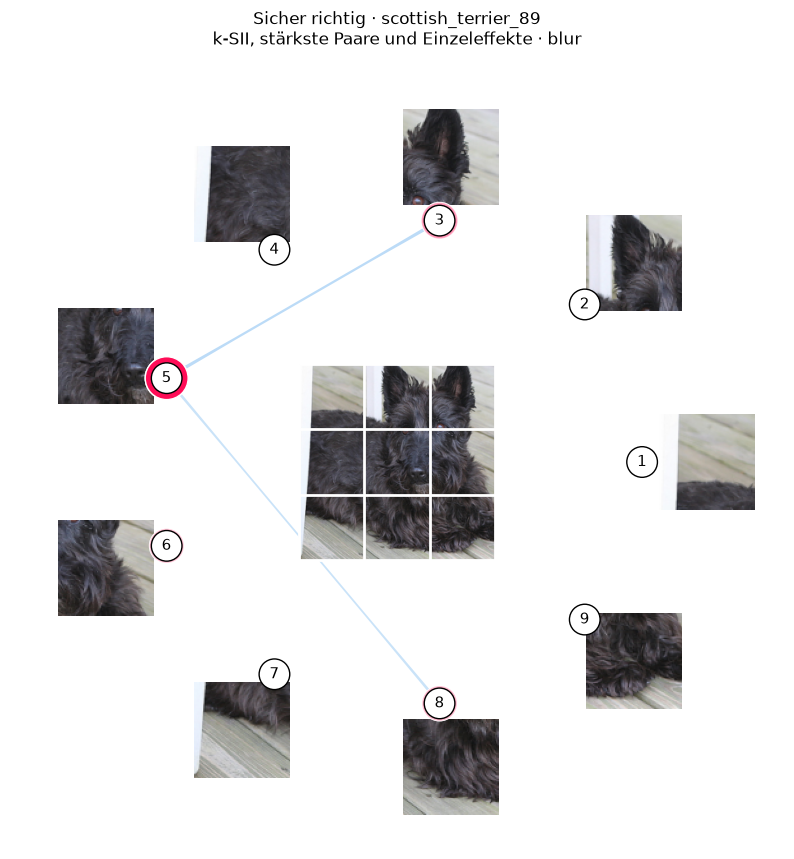

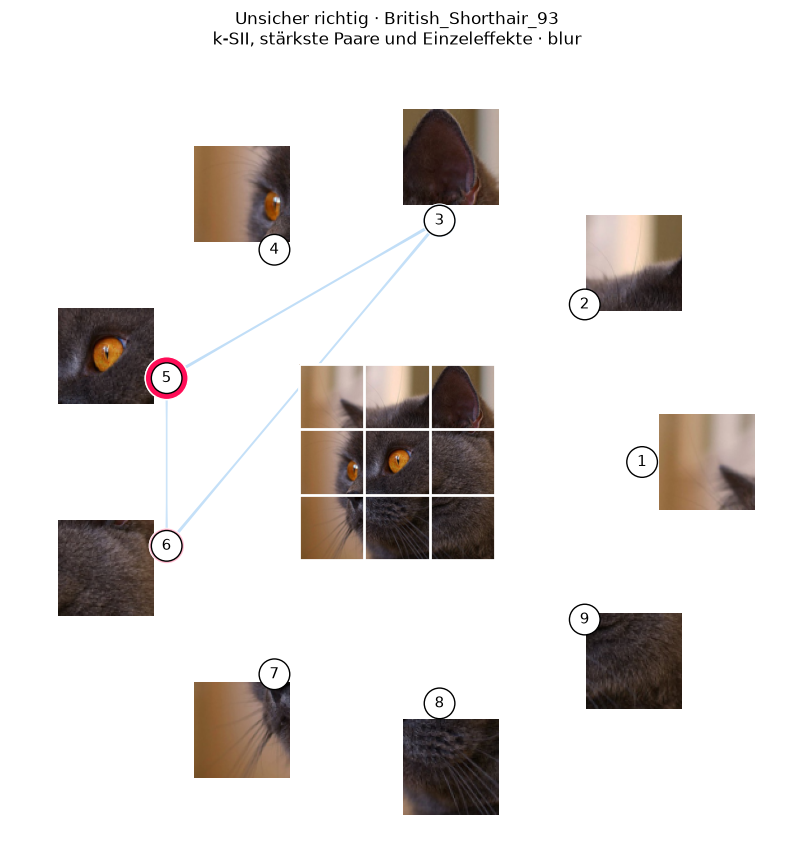

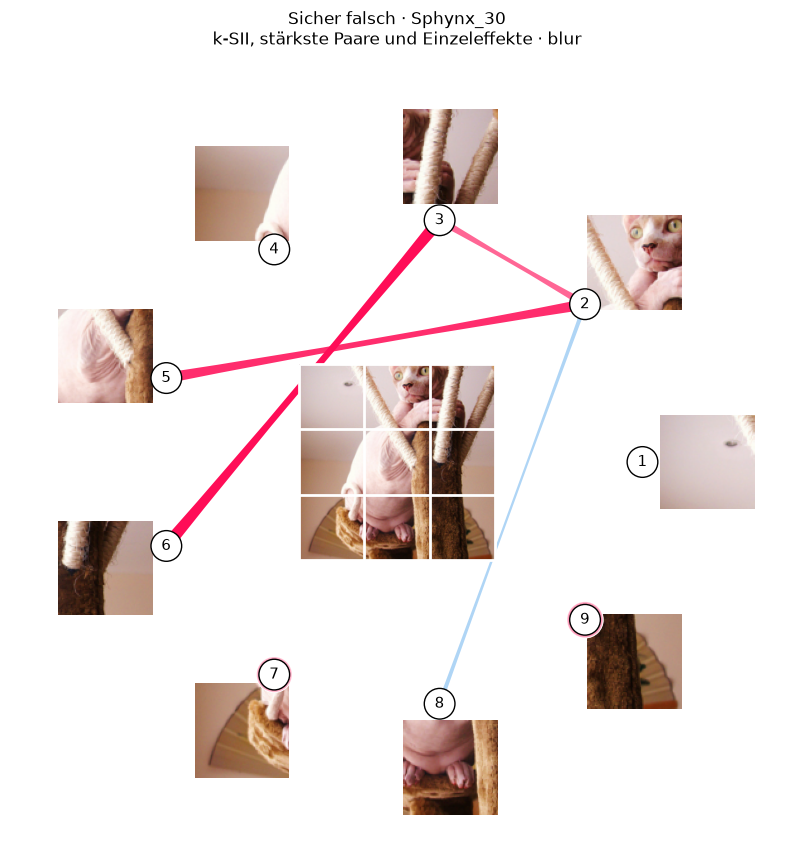

,Fall,Bild,Rang,Region A,Region B,k-SII
0,Sicher richtig,scottish_terrier_89,1,3,5,-0.23355
1,Sicher richtig,scottish_terrier_89,2,5,8,-0.18240
2,Sicher richtig,scottish_terrier_89,3,5,6,-0.18002
3,Sicher richtig,scottish_terrier_89,4,5,9,-0.10699
4,Sicher richtig,scottish_terrier_89,5,2,5,-0.09014
5,Unsicher richtig,British_Shorthair_93,1,3,5,-0.21640
6,Unsicher richtig,British_Shorthair_93,2,3,6,-0.20597
7,Unsicher richtig,British_Shorthair_93,3,5,6,-0.17559
8,Unsicher richtig,British_Shorthair_93,4,1,2,0.12312
9,Unsicher richtig,British_Shorthair_93,5,4,6,0.08761


In [6]:
pair_rows = []
for case in cases:
    payload = load_record(find_record(case["image_id"]))
    sv, ksii = image_explanations(payload)
    n = payload["coalitions"].shape[1]
    ranked_pairs = sorted(
        [(i, j, float(payload["ksii_pairs"][i, j])) for i in range(n) for j in range(i+1, n)],
        key=lambda item: abs(item[2]), reverse=True,
    )
    for rank, (i, j, value) in enumerate(ranked_pairs[:5], start=1):
        pair_rows.append({"Fall": case["role"], "Bild": case["image_id"], "Rang": rank,
                          "Region A": i+1, "Region B": j+1, "k-SII": value})
    game = make_image_game(payload["crop"].numpy(), payload["regions"].numpy(), "blur", payload["target_class"])
    fig, ax = si_graph_plot(
        ksii, show=False, n_interactions=6, center_image=payload["crop"].numpy(),
        feature_image_patches=game.player_images(), feature_names=[str(i+1) for i in range(n)],
        feature_image_patches_size=0.17, plot_original_nodes=True,
    )
    fig.set_size_inches(9, 9)
    # Keep all native thumbnails visible; datalim aspect adjustment can ignore fixed limits.
    image_extents = np.asarray([artist.get_extent() for artist in ax.images], dtype=float)
    bound = max(1.25, float(np.abs(image_extents).max())) + 0.12
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-bound, bound)
    ax.set_ylim(-bound, bound)
    ax.set_autoscale_on(False)
    fig.subplots_adjust(left=0.04, right=0.96, bottom=0.04, top=0.90)
    ax.set_title(f"{case['role']} · {case['image_id']}\nk-SII, stärkste Paare und Einzeleffekte · blur", pad=22)
    plt.show()
display(pd.DataFrame(pair_rows).round(5))


## 7. Tier und Hintergrund über alle 37 Rassen

- Für jeden Regionsbeitrag verteilen wir die Masse gleichmäßig auf **seine eigenen Pixel**.
  So erhalten große Superpixel nicht allein durch ihre Größe mehr Gewicht.
- Signierte Masse beantwortet, ob Hinweise die Zielklasse insgesamt unterstützen.
  Absolute Masse beschreibt, wo starke Beiträge liegen; sie ist nicht mit dem signierten
  Gesamtunterschied gleichzusetzen.
- Der unklassifizierte Trimap-Bereich bleibt separat. Auch ein großer Hintergrundanteil
  ist ein Befund über dieses Modell und dieses Maskierungsspiel, kein Kausalitätsnachweis.
- Das zusätzliche semantische Spiel prüft Tier-only und Hintergrund-only direkt. Seine
  Beiträge sind wegen anderer Spieler nicht identisch mit den aufgeteilten Raster-SV.


,Richtig,p(Vollbild),p(Referenz) / blur,p(Referenz) / mean,Masse Tier / blur,Masse Tier / mean,Masse Hintergrund / blur,Masse Hintergrund / mean,Masse unklassifiziert / blur,Masse unklassifiziert / mean
Rasse,,,,,,,,,,
Abyssinian,False,0.496,0.0122,0.0123,0.4513,0.4371,0.3524,0.3543,0.1963,0.2086
American Bulldog,False,0.643,0.00155,0.0114,0.5769,0.5546,0.2542,0.2788,0.1689,0.1666
American Pit Bull Terrier,False,0.629,0.00247,0.00293,0.6146,0.6040,0.2371,0.2355,0.1482,0.1605
Basset Hound,True,0.986,0.00681,0.00978,0.3915,0.4349,0.3102,0.2750,0.2983,0.2901
Beagle,True,0.973,0.0181,0.0253,0.6165,0.6278,0.1761,0.1613,0.2074,0.2108
Bengal,True,0.831,0.128,0.135,0.5896,0.5478,0.2570,0.2991,0.1535,0.1532
Birman,False,0.576,0.00773,0.0518,0.5730,0.6767,0.2202,0.1906,0.2068,0.1327
Bombay,True,0.95,0.234,0.0411,0.4358,0.3585,0.4583,0.5318,0.1059,0.1097
Boxer,True,0.991,0.00134,0.0113,0.4889,0.4811,0.1479,0.1399,0.3632,0.3789


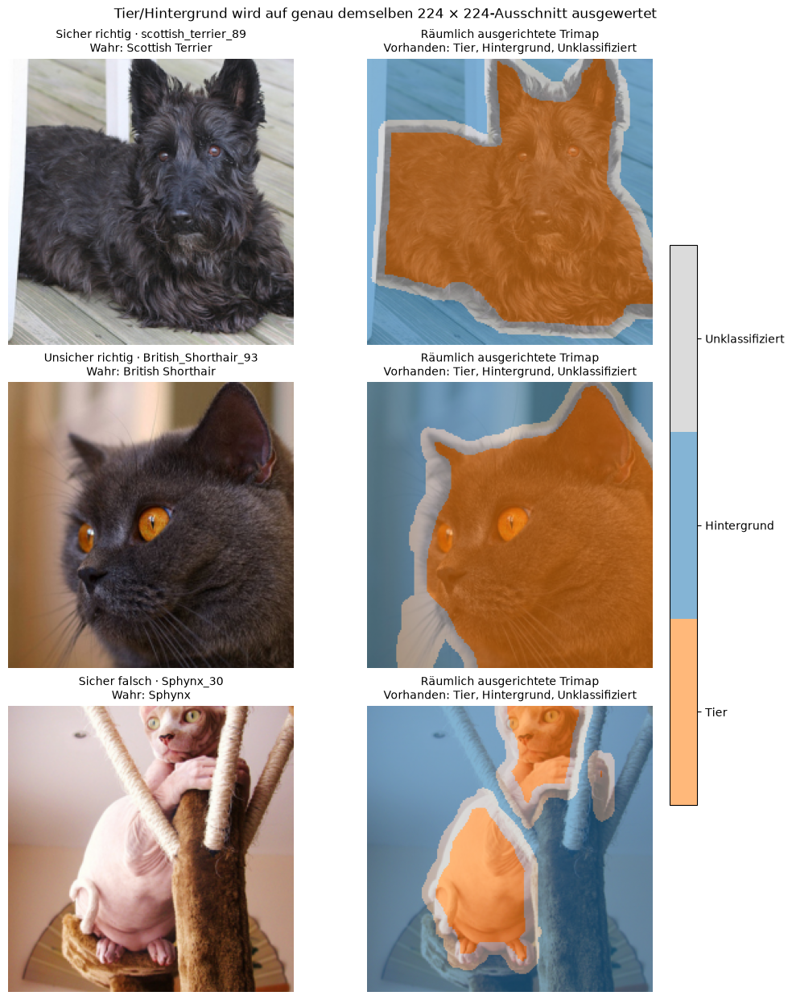

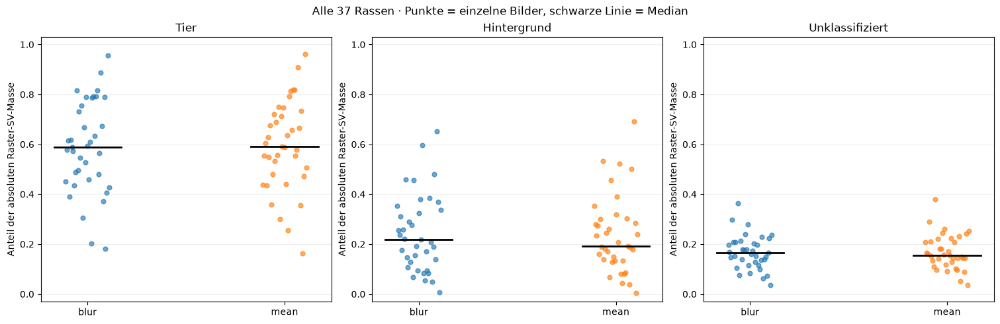

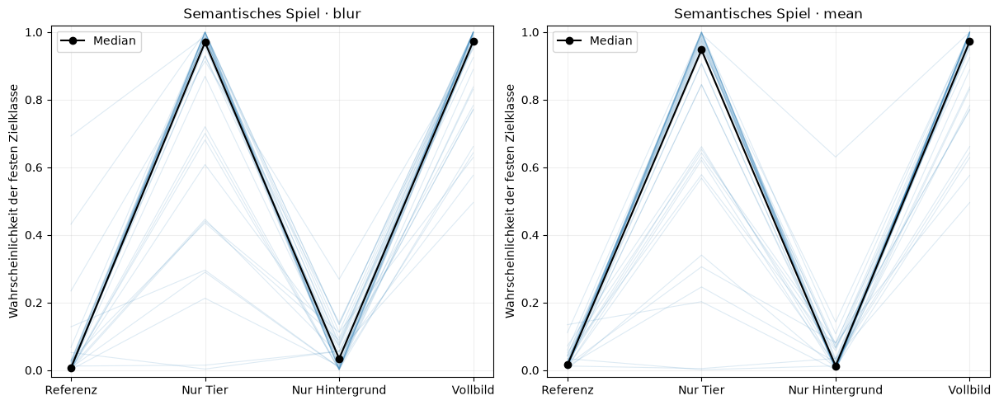

In [7]:
TRIMAP_NAMES = {1: "Tier", 2: "Hintergrund", 3: "Unklassifiziert"}

def attribution_summary(payload: dict) -> dict:
    """Allocate regional attribution mass by fractional trimap overlap without area bias."""
    regions, trimap = payload["regions"].numpy(), payload["trimap"].numpy()
    values = payload["sv"].double().numpy()
    n = len(values)
    fractions = np.array([
        [np.mean(trimap[regions == player] == label) for player in range(n)]
        for label in (1, 2, 3)
    ])
    np.testing.assert_allclose(fractions.sum(axis=0), 1)
    total_abs = float(np.abs(values).sum())
    result = {"absolute_sv_mass": total_abs}
    for row, label in enumerate((1, 2, 3)):
        result[f"signed_mass_{label}"] = float(fractions[row] @ values)
        result[f"absolute_mass_{label}"] = float(fractions[row] @ np.abs(values))
        result[f"mass_fraction_{label}"] = float(fractions[row] @ np.abs(values) / total_abs) if total_abs > 0 else np.nan
        result[f"area_fraction_{label}"] = float(np.mean(trimap == label))
    np.testing.assert_allclose(sum(result[f"signed_mass_{label}"] for label in (1,2,3)), values.sum(), atol=1e-7)
    pair_values = payload["ksii_pairs"].double().numpy()
    pair_totals = {"tier_tier": 0.0, "hintergrund_hintergrund": 0.0, "gemischt": 0.0, "unklassifiziert": 0.0}
    for i in range(n):
        for j in range(i+1, n):
            weight = abs(pair_values[i,j])
            fg = fractions[0,i] * fractions[0,j]
            bg = fractions[1,i] * fractions[1,j]
            mixed = fractions[0,i] * fractions[1,j] + fractions[1,i] * fractions[0,j]
            pair_totals["tier_tier"] += weight * fg
            pair_totals["hintergrund_hintergrund"] += weight * bg
            pair_totals["gemischt"] += weight * mixed
            pair_totals["unklassifiziert"] += weight * max(0.0, 1-fg-bg-mixed)
    result.update({f"pair_mass_{key}": float(value) for key, value in pair_totals.items()})
    return result


summary_rows = []
for record in records:
    payload = load_record(record)
    row = {key: record[key] for key in ("image_id", "test_index", "target_class", "true_class", "regions_kind", "fill", "n_players")}
    row.update({"breed": classes[record["true_class"]], "correct": record["target_class"] == record["true_class"],
                "p_empty": payload["sv_baseline"], "p_full": float(payload["baseline_scores"][-1]),
                "delta_probability": float(payload["baseline_scores"][-1]) - payload["sv_baseline"]})
    row.update(attribution_summary(payload))
    if record["regions_kind"] == "semantic":
        semantic_labels = record["semantic_labels"]
        for label in (1,2,3):
            code = 1 << semantic_labels.index(label) if label in semantic_labels else 0
            row[f"only_label_{label}_probability"] = float(payload["baseline_scores"][code])
        row["absent_labels"] = ",".join(map(str, record["absent_semantic_labels"]))
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
summary.to_csv(SHAPIQ_DIR / "cohort_summary.csv", index=False)
grid_summary = summary[summary.regions_kind == "grid"].copy()
semantic_summary = summary[summary.regions_kind == "semantic"].copy()
# One row per breed, with the two references beside one another rather than truncated 74 rows.
reference_fields = ["p_empty", "mass_fraction_1", "mass_fraction_2", "mass_fraction_3"]
reference_table = grid_summary.pivot(index="breed", columns="fill", values=reference_fields).reindex(classes)
field_names = {
    "p_empty": "p(Referenz)", "mass_fraction_1": "Masse Tier",
    "mass_fraction_2": "Masse Hintergrund", "mass_fraction_3": "Masse unklassifiziert",
}
reference_table.columns = [f"{field_names[field]} / {fill}" for field, fill in reference_table.columns]
cohort_table = (
    grid_summary[grid_summary.fill == "blur"].set_index("breed")[["correct", "p_full"]]
    .rename(columns={"correct": "Richtig", "p_full": "p(Vollbild)"})
    .join(reference_table).reindex(classes)
)
cohort_table.index.name = "Rasse"
cohort_table.to_csv(SHAPIQ_DIR / "cohort_table.csv")
with pd.option_context("display.max_rows", 40, "display.max_columns", 20):
    display(cohort_table.style.format(
        {column: "{:.3g}" if column.startswith("p(") else "{:.4f}"
         for column in cohort_table.select_dtypes(include="number").columns},
        na_rep="–",
    ))

# The trimap shown here has exactly the same geometry as every mask and model input.
if cases:
    from matplotlib.colors import ListedColormap
    trimap_cmap = ListedColormap(["tab:orange", "tab:blue", "0.75"])
    fig, axes = plt.subplots(len(cases), 2, figsize=(10, 4.1 * len(cases)), squeeze=False, layout="constrained")
    for row, case in enumerate(cases):
        payload = load_record(find_record(case["image_id"]))
        crop, trimap = payload["crop"].numpy(), payload["trimap"].numpy()
        axes[row, 0].imshow(crop)
        axes[row, 0].set_title(f"{case['role']} · {case['image_id']}\nWahr: {classes[payload['true_class']]}", fontsize=10)
        axes[row, 1].imshow(crop)
        overlay = axes[row, 1].imshow(trimap, cmap=trimap_cmap, vmin=0.5, vmax=3.5, alpha=0.55)
        present = ", ".join(TRIMAP_NAMES[int(label)] for label in np.unique(trimap))
        axes[row, 1].set_title(f"Räumlich ausgerichtete Trimap\nVorhanden: {present}", fontsize=10)
        for ax in axes[row]:
            ax.axis("off")
    colorbar = fig.colorbar(overlay, ax=axes[:, 1].tolist(), ticks=[1, 2, 3], shrink=0.6)
    colorbar.ax.set_yticklabels([TRIMAP_NAMES[label] for label in (1, 2, 3)])
    fig.suptitle("Tier/Hintergrund wird auf genau demselben 224 × 224-Ausschnitt ausgewertet")
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
for col, (label, name) in enumerate(TRIMAP_NAMES.items()):
    for offset, fill in enumerate(FILLS):
        sub = grid_summary[grid_summary.fill == fill]
        jitter = np.linspace(-0.11, 0.11, len(sub))
        axes[col].scatter(np.full(len(sub), offset)+jitter, sub[f"mass_fraction_{label}"], alpha=0.65, s=24)
        axes[col].plot([offset-0.17, offset+0.17], [sub[f"mass_fraction_{label}"].median()]*2, color="black", linewidth=2)
    axes[col].set(title=name, xticks=[0,1], xticklabels=FILLS, ylim=(-0.03,1.03), ylabel="Anteil der absoluten Raster-SV-Masse")
    axes[col].grid(axis="y", alpha=0.2)
fig.suptitle("Alle 37 Rassen · Punkte = einzelne Bilder, schwarze Linie = Median")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, fill in zip(axes, FILLS, strict=True):
    sub = semantic_summary[semantic_summary.fill == fill]
    names = ["Referenz", "Nur Tier", "Nur Hintergrund", "Vollbild"]
    fields = ["p_empty", "only_label_1_probability", "only_label_2_probability", "p_full"]
    for _, row in sub.iterrows():
        ax.plot(names, [row[field] for field in fields], color="tab:blue", alpha=0.15, linewidth=0.8)
    ax.plot(names, [sub[field].median() for field in fields], color="black", marker="o", label="Median")
    ax.set(title=f"Semantisches Spiel · {fill}", ylabel="Wahrscheinlichkeit der festen Zielklasse", ylim=(-0.02,1.02))
    ax.legend(); ax.grid(alpha=0.2)
plt.show()


## 8. Referenzrobustheit und Superpixel-Diagnosen

- Ein hoher Zusammenhang über beide Referenzen spricht für Robustheit innerhalb dieser
  beiden Spiele. Ein niedriger Zusammenhang oder ein Vorzeichenwechsel ist ebenfalls ein Ergebnis.
- Wir vergleichen dieselben neun Rasterspieler. Konstanten Vektoren wird keine künstliche
  Korrelation zugewiesen; solche Fälle bleiben als fehlend markiert.
- Die Superpixelbilder verwenden die tatsächlichen Regionsgrenzen. Für diese Graphen
  wird kein automatisch erzeugtes quadratisches Bildraster eingeblendet.


,image_id,breed,correct,sv_rank_correlation,pair_rank_correlation,sv_sign_flips,top3_overlap,empty_blur,empty_mean,sv_l1_difference
0,Abyssinian_79,Abyssinian,False,0.8000,0.8136,0,0.6667,0.0122,0.0123,0.2112
1,american_bulldog_208,American Bulldog,False,0.9667,0.4739,0,0.6667,0.0016,0.0114,0.1388
2,american_pit_bull_terrier_42,American Pit Bull Terrier,False,0.8833,0.6322,1,1.0000,0.0025,0.0029,0.2869
3,basset_hound_66,Basset Hound,True,0.3000,0.4842,1,0.6667,0.0068,0.0098,0.3314
4,beagle_38,Beagle,True,0.9000,0.7169,1,1.0000,0.0181,0.0253,0.3204
5,Bengal_196,Bengal,True,0.9167,0.9246,0,1.0000,0.1282,0.1346,0.2893
6,Birman_99,Birman,False,0.2333,0.4103,3,0.6667,0.0077,0.0518,0.5422
7,Bombay_214,Bombay,True,0.9667,0.0520,1,1.0000,0.2342,0.0411,0.3771
8,boxer_39,Boxer,True,0.9000,0.7145,2,0.6667,0.0013,0.0113,0.3090
9,British_Shorthair_93,British Shorthair,True,0.9167,0.5833,0,0.6667,0.0039,0.0249,0.4559


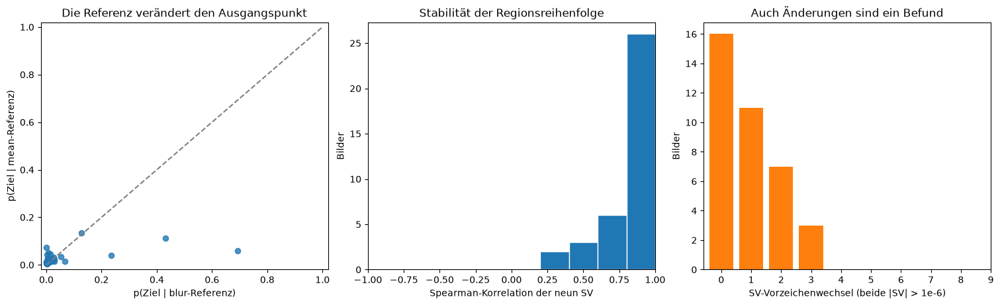

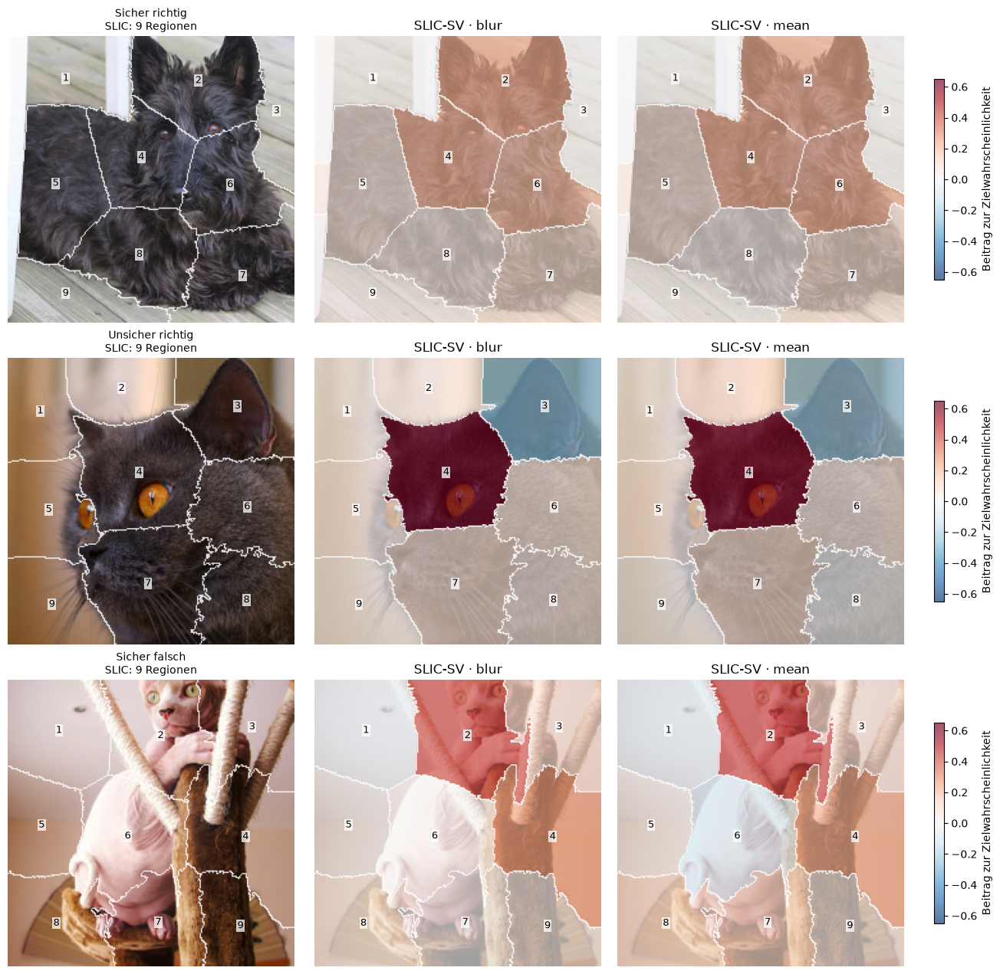

In [8]:
def rank_correlation(left: np.ndarray, right: np.ndarray) -> float:
    """Return rank correlation, or NaN when one vector is constant."""
    left_rank, right_rank = pd.Series(left).rank().to_numpy(), pd.Series(right).rank().to_numpy()
    if np.ptp(left_rank) == 0 or np.ptp(right_rank) == 0:
        return np.nan
    return float(np.corrcoef(left_rank, right_rank)[0,1])


robustness_rows = []
for image_id in cohort_ids:
    left, right = [load_record(find_record(image_id, fill=fill)) for fill in FILLS]
    sv_left, sv_right = left["sv"].numpy(), right["sv"].numpy()
    n = len(sv_left)
    upper = np.triu_indices(n, 1)
    significant = (np.abs(sv_left) > 1e-6) & (np.abs(sv_right) > 1e-6)
    top_left, top_right = set(np.argsort(np.abs(sv_left))[-3:]), set(np.argsort(np.abs(sv_right))[-3:])
    robustness_rows.append({
        "image_id": image_id, "breed": classes[left["true_class"]],
        "correct": left["target_class"] == left["true_class"],
        "sv_rank_correlation": rank_correlation(sv_left, sv_right),
        "pair_rank_correlation": rank_correlation(left["ksii_pairs"].numpy()[upper], right["ksii_pairs"].numpy()[upper]),
        "sv_sign_flips": int(((np.sign(sv_left) != np.sign(sv_right)) & significant).sum()),
        "top3_overlap": len(top_left & top_right)/3,
        "empty_blur": left["sv_baseline"], "empty_mean": right["sv_baseline"],
        "sv_l1_difference": float(np.abs(sv_left-sv_right).sum()),
    })
robustness = pd.DataFrame(robustness_rows)
robustness.to_csv(SHAPIQ_DIR / "reference_robustness.csv", index=False)
display(robustness.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
axes[0].scatter(robustness.empty_blur, robustness.empty_mean, s=35, alpha=0.8)
axes[0].plot([0,1],[0,1], "--", color="0.5")
axes[0].set(xlabel="p(Ziel | blur-Referenz)", ylabel="p(Ziel | mean-Referenz)", xlim=(-0.02,1.02), ylim=(-0.02,1.02), title="Die Referenz verändert den Ausgangspunkt")
axes[1].hist(robustness.sv_rank_correlation.dropna(), bins=np.linspace(-1,1,11), color="tab:blue", edgecolor="white")
axes[1].set(xlabel="Spearman-Korrelation der neun SV", ylabel="Bilder", title="Stabilität der Regionsreihenfolge", xlim=(-1,1))
counts = robustness.sv_sign_flips.value_counts().sort_index()
axes[2].bar(counts.index, counts.values, color="tab:orange")
axes[2].set(xlabel="SV-Vorzeichenwechsel (beide |SV| > 1e-6)", ylabel="Bilder", title="Auch Änderungen sind ein Befund", xticks=list(range(10)))
plt.show()

if cases:
    slic_limit = max(
        float(load_record(find_record(case["image_id"], "slic", fill))["sv"].abs().max())
        for case in cases for fill in FILLS
    )
    slic_norm = TwoSlopeNorm(vmin=-max(slic_limit, 1e-8), vcenter=0, vmax=max(slic_limit, 1e-8))
    fig, axes = plt.subplots(len(cases), 3, figsize=(13, 4.2*len(cases)), squeeze=False, layout="constrained")
    for row, case in enumerate(cases):
        payloads = [load_record(find_record(case["image_id"], "slic", fill)) for fill in FILLS]
        first = payloads[0]
        axes[row,0].imshow(first["crop"].numpy()); show_region_boundaries(axes[row,0], first)
        axes[row,0].set_title(f"{case['role']}\nSLIC: {len(first['sv'])} Regionen", fontsize=10)
        norm = slic_norm
        for col, (fill, payload) in enumerate(zip(FILLS,payloads,strict=True),start=1):
            axes[row,col].imshow(payload["crop"].numpy())
            heat = axes[row,col].imshow(region_map(payload,payload["sv"].numpy()),cmap="RdBu_r",norm=norm,alpha=0.65)
            show_region_boundaries(axes[row,col],payload)
            axes[row,col].set_title(f"SLIC-SV · {fill}")
        for ax in axes[row]: ax.axis("off")
        fig.colorbar(heat,ax=axes[row,1:].tolist(),shrink=0.7,label="Beitrag zur Zielwahrscheinlichkeit")
    plt.show()


## 9. Wie viel Budget reicht? Vergleich mit der exakten Rechnung

- Für **alle 37 Rasterbilder und beide Referenzen** vergleichen wir KernelSHAP (SV) und
  KernelSHAPIQ (k-SII Ordnung 2) bei 64, 128, 256 und 512 Koalitionen über drei Seeds.
- Alle Spielwerte stehen bereits im Cache. Dieser Vergleich löst **keine neue CNN-Inferenz** aus.
- RMSE wird für Einzeleffekte und Paare getrennt gemessen. Die Fehler für SV und
  k-SII-Einzeleffekte beziehen sich auf jeweils ihre eigene exakte Definition.
- 512 Koalitionen entsprechen dem Vollbudget; kleine numerische Abweichungen sind möglich.
  Die Zahlen beschreiben diese Kohorte und diese Spiele, keine universelle Budgetgarantie.


Budgetvergleich: 10/74 Tabellen, 0.8 s


Budgetvergleich: 20/74 Tabellen, 1.5 s


Budgetvergleich: 30/74 Tabellen, 2.3 s


Budgetvergleich: 40/74 Tabellen, 3.2 s


Budgetvergleich: 50/74 Tabellen, 4.0 s


Budgetvergleich: 60/74 Tabellen, 4.8 s


Budgetvergleich: 70/74 Tabellen, 5.6 s


Budgetvergleich: 74/74 Tabellen, 5.9 s


rmse_single           rmse_pair             seconds  \
                                mean       std      mean       std      mean   
method       fill budget                                                       
KernelSHAP   blur 64        0.045450  0.018673       NaN       NaN  0.001066   
                  128       0.027897  0.011971       NaN       NaN  0.002176   
                  256       0.013663  0.005949       NaN       NaN  0.003455   
                  512       0.000000  0.000000       NaN       NaN  0.001084   
             mean 64        0.042786  0.018848       NaN       NaN  0.001047   
                  128       0.025974  0.011969       NaN       NaN  0.002160   
                  256       0.012904  0.005686       NaN       NaN  0.003421   
                  512       0.000000  0.000000       NaN       NaN  0.001050   
KernelSHAPIQ blur 64        0.045450  0.018673  0.117863  0.064653  0.001419   
                  128       0.027897  0.011971  0.052066  0.029550  0.002660   
                  256       0.013663  0.005949  0.020011  0.010863  0.004226   
                  512       0.000000  0.000000  0.000000  0.000000  0.001737   
             mean 64        0.042786  0.018848  0.105034  0.048039  0.001344   
                  128       0.025974  0.011969  0.045370  0.021033  0.002524   
                  256       0.012904  0.005686  0.017732  0.007409  0.003895   
                  512       0.000000  0.000000  0.000000  0.000000  0.001700   

                                    
                               std  
method       fill budget            
KernelSHAP   blur 64      0.000316  
                  128     0.000282  
                  256     0.000329  
                  512     0.000244  
             mean 64      0.000245  
                  128     0.000312  
                  256     0.000280  
                  512     0.000101  
KernelSHAPIQ blur 64      0.000341  
                  128     0.000779  
                  256     0.001694  
                  512     0.000418  
             mean 64      0.000227  
                  128     0.000224  
                  256     0.000392  
                  512     0.000198

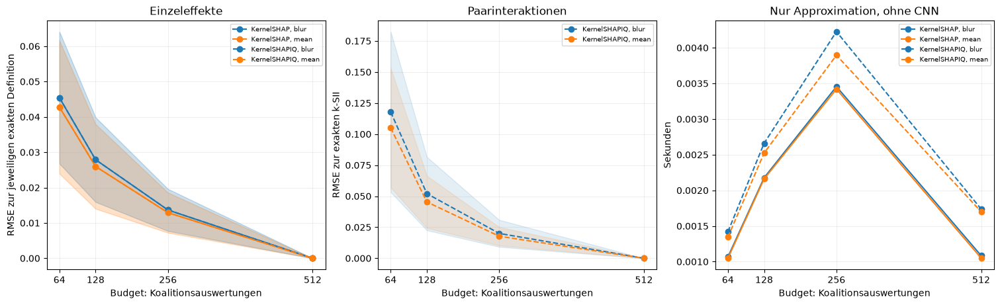

In [9]:
benchmark_rows = []
cnn_before_benchmark = CNN_IMAGE_EVALUATIONS
benchmark_start = time.perf_counter()
for position, record in enumerate([r for r in records if r["regions_kind"] == "grid"], start=1):
    payload = load_record(record)
    scores = payload["baseline_scores"].double().numpy()
    n = payload["coalitions"].shape[1]
    game = score_callable(scores, n)
    exact_sv, exact_ksii, *_ = exact_values(scores, n)
    upper_pairs = [(i,j) for i in range(n) for j in range(i+1,n)]
    for method in ("KernelSHAP", "KernelSHAPIQ"):
        for budget in APPROXIMATION_BUDGETS:
            for seed in APPROXIMATION_SEEDS:
                approximator = (
                    shapiq.KernelSHAP(n=n, random_state=seed)
                    if method == "KernelSHAP"
                    else shapiq.KernelSHAPIQ(n=n, index="k-SII", max_order=2, random_state=seed)
                )
                start = time.perf_counter()
                result = approximator.approximate(budget=budget, game=game)
                elapsed = time.perf_counter() - start
                truth = exact_sv if method == "KernelSHAP" else exact_ksii
                single_error = np.array([result[(i,)]-truth[(i,)] for i in range(n)])
                pair_error = np.array([result[pair]-truth[pair] for pair in upper_pairs]) if method == "KernelSHAPIQ" else None
                if budget == 2**n:
                    np.testing.assert_allclose(single_error, 0, atol=1e-5)
                    if pair_error is not None: np.testing.assert_allclose(pair_error, 0, atol=1e-5)
                benchmark_rows.append({
                    "image_id": record["image_id"], "fill": record["fill"], "method": method,
                    "budget": budget, "seed": seed,
                    "rmse_single": float(np.sqrt(np.mean(single_error**2))),
                    "rmse_pair": float(np.sqrt(np.mean(pair_error**2))) if pair_error is not None else np.nan,
                    "seconds": elapsed,
                })
    if position % 10 == 0 or position == 74:
        print(f"Budgetvergleich: {position}/74 Tabellen, {time.perf_counter()-benchmark_start:.1f} s")
assert CNN_IMAGE_EVALUATIONS == cnn_before_benchmark
benchmark = pd.DataFrame(benchmark_rows)
benchmark.to_csv(SHAPIQ_DIR / "approximation_benchmark.csv", index=False)
display(benchmark.groupby(["method","fill","budget"])[["rmse_single","rmse_pair","seconds"]].agg(["mean","std"]).round(6))

fig, axes = plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
for method, linestyle in (("KernelSHAP","-"),("KernelSHAPIQ","--")):
    for fill, color in (("blur","tab:blue"),("mean","tab:orange")):
        sub = benchmark[(benchmark.method==method)&(benchmark.fill==fill)]
        for ax, field in ((axes[0],"rmse_single"),(axes[1],"rmse_pair"),(axes[2],"seconds")):
            if field=="rmse_pair" and method=="KernelSHAP": continue
            grouped = sub.groupby("budget")[field]
            average, deviation = grouped.mean(), grouped.std().fillna(0)
            ax.plot(average.index, average, marker="o", linestyle=linestyle, color=color, label=f"{method}, {fill}")
            if field!="seconds":
                ax.fill_between(average.index,np.maximum(0,average-deviation),average+deviation,color=color,alpha=0.12)
for ax,title,ylabel in zip(axes,["Einzeleffekte","Paarinteraktionen","Nur Approximation, ohne CNN"],["RMSE zur jeweiligen exakten Definition","RMSE zur exakten k-SII","Sekunden"],strict=True):
    ax.set(title=title,xlabel="Budget: Koalitionsauswertungen",ylabel=ylabel,xticks=APPROXIMATION_BUDGETS)
    ax.grid(alpha=0.2); ax.legend(fontsize=7)
plt.show()


## 10. Warum Rasse A statt Rasse B?

- Beim Fehler vergleichen wir Vorhersage A mit der tatsächlichen Rasse B; beim richtigen
  Treffer mit der zweitplatzierten Rasse.
- Das Ziel ist jetzt **Logit(A) − Logit(B)**. Positive Beiträge unterstützen A relativ zu B,
  negative unterstützen B. Die Einheit ist eine Logit-Differenz, keine Wahrscheinlichkeit.
- Beide Klassen werden vorab festgelegt. Der Merkmals- und Logitcache reicht für sämtliche
  Kontraste; zusätzliche CNN-Auswertungen sind nicht erforderlich.
- Bei Fehlern zeigen wir daneben die gewöhnlichen SV der tatsächlichen Klassenwahrscheinlichkeit.

- Jede Heatmap-Spalte teilt einen gemeinsamen symmetrischen Farbbereich über alle Fälle;
  Logit-Margen und Wahrscheinlichkeitsbeiträge bleiben wegen ihrer unterschiedlichen
  Einheiten getrennt skaliert.


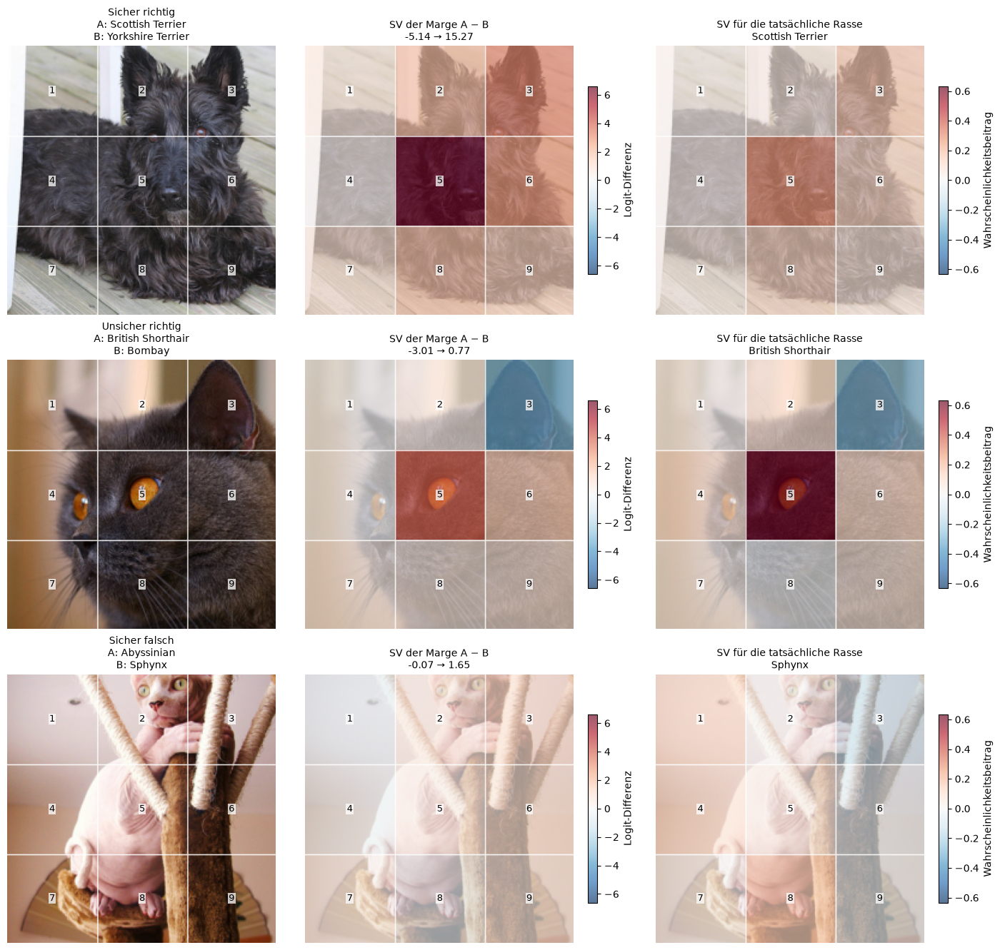

,image_id,role,class_A,class_B,margin_empty,margin_full,strongest_pair,pair_value
0,scottish_terrier_89,Sicher richtig,Scottish Terrier,Yorkshire Terrier,-5.1435,15.2655,"5, 6",-3.7849
1,British_Shorthair_93,Unsicher richtig,British Shorthair,Bombay,-3.0103,0.7723,"3, 6",-2.0730
2,Sphynx_30,Sicher falsch,Abyssinian,Sphynx,-0.0664,1.6499,"2, 5",2.1172


In [10]:
contrast_rows = []
if cases:
    contrast_limits = {"margin": 1e-8, "true_probability": 1e-8}
    for case in cases:
        payload = load_record(find_record(case["image_id"]))
        n = payload["coalitions"].shape[1]
        a, b = int(payload["target_class"]), int(case["comparison_class"])
        logits = payload["baseline_logits"].double().numpy()
        margin_values = exact_values(logits[:, a] - logits[:, b], n)[2]
        true_scores = payload["baseline_logits"].softmax(1)[:, payload["true_class"]].double().numpy()
        true_values = exact_values(true_scores, n)[2]
        contrast_limits["margin"] = max(contrast_limits["margin"], float(np.abs(margin_values).max()))
        contrast_limits["true_probability"] = max(contrast_limits["true_probability"], float(np.abs(true_values).max()))
    fig, axes = plt.subplots(len(cases),3,figsize=(14,4.4*len(cases)),squeeze=False,layout="constrained")
    for row,case in enumerate(cases):
        payload = load_record(find_record(case["image_id"]))
        n = payload["coalitions"].shape[1]
        a,b = int(payload["target_class"]),int(case["comparison_class"])
        logits = payload["baseline_logits"].double().numpy()
        margin = logits[:,a]-logits[:,b]
        sv_margin,ksii_margin,margin_single,_,margin_pairs = exact_values(margin,n)
        true_scores = payload["baseline_logits"].softmax(1)[:,payload["true_class"]].double().numpy()
        _,_,true_single,_,_ = exact_values(true_scores,n)
        axes[row,0].imshow(payload["crop"].numpy()); show_region_boundaries(axes[row,0],payload)
        axes[row,0].set_title(f"{case['role']}\nA: {classes[a]}\nB: {classes[b]}",fontsize=10)
        for col,values,title,unit in (
            (1,margin_single,f"SV der Marge A − B\n{margin[0]:.2f} → {margin[-1]:.2f}","Logit-Differenz"),
            (2,true_single,f"SV für die tatsächliche Rasse\n{classes[payload['true_class']]}","Wahrscheinlichkeitsbeitrag"),
        ):
            limit = contrast_limits["margin" if col == 1 else "true_probability"]
            axes[row,col].imshow(payload["crop"].numpy())
            heat=axes[row,col].imshow(region_map(payload,values),cmap="RdBu_r",norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),alpha=0.65)
            show_region_boundaries(axes[row,col],payload)
            axes[row,col].set_title(title,fontsize=10)
            fig.colorbar(heat,ax=axes[row,col],shrink=0.7,label=unit)
        for ax in axes[row]: ax.axis("off")
        pairs=sorted([(i,j,margin_pairs[i,j]) for i in range(n) for j in range(i+1,n)],key=lambda item:abs(item[2]),reverse=True)
        contrast_rows.append({"image_id":case["image_id"],"role":case["role"],"class_A":classes[a],"class_B":classes[b],"margin_empty":float(margin[0]),"margin_full":float(margin[-1]),"strongest_pair":f"{pairs[0][0]+1}, {pairs[0][1]+1}","pair_value":float(pairs[0][2])})
    plt.show()
contrast_summary=pd.DataFrame(contrast_rows)
contrast_summary.to_csv(SHAPIQ_DIR / "contrastive_diagnostics.csv",index=False)
display(contrast_summary.round(4))


## 11. Ergebnisse lesen, auch wenn sie Erwartungen widersprechen

- Die folgenden Aussagen werden aus den berechneten Tabellen erzeugt. Einzelne Fälle
  erklären kein allgemeines Rassenverhalten: pro Rasse wurde genau ein Bild ausgewählt.
- Ein hoher Referenzwert, schwache Interaktionen oder starke Referenzabhängigkeit sind
  aussagekräftige Ergebnisse und werden nicht als Misserfolg ausgeblendet.
- Die Segmentierung ist nur Auswertungsinformation. Sie war weder Modelleingabe noch
  Trainingsziel und beweist keine kausale Erklärung.
- Der Folgeversuch übernimmt dieselben Regionen, Koalitionen und VGG-Merkmale. Er setzt
  mehrere Köpfe darauf und erklärt dann zusätzlich Gesamt-, aleatorische und epistemische
  Modellunsicherheit. Die hier verwendeten Wahrscheinlichkeiten bleiben unkalibriert.


In [11]:
findings = []
for fill in FILLS:
    sub = grid_summary[grid_summary.fill==fill]
    semantic = semantic_summary[semantic_summary.fill==fill]
    foreground_share = sub.mass_fraction_1.median()
    background_share = sub.mass_fraction_2.median()
    baseline_not_lower = int((sub.p_empty>=sub.p_full).sum())
    findings.append(
        f"**{fill}:** Median der absoluten Raster-SV-Masse: Tier {foreground_share:.1%}, "
        f"Hintergrund {background_share:.1%}. Bei {baseline_not_lower}/37 Bildern war die "
        f"Zielwahrscheinlichkeit der Referenz mindestens so hoch wie im Vollbild. "
        f"Im semantischen Spiel beträgt der Median für Tier-only "
        f"{semantic.only_label_1_probability.median():.3g}, für Hintergrund-only "
        f"{semantic.only_label_2_probability.median():.3g}."
    )
valid_corr=robustness.sv_rank_correlation.dropna()
findings.append(
    f"**Referenzvergleich:** Median der SV-Rangkorrelation "
    f"{valid_corr.median():.3f} ({len(valid_corr)}/37 definierte Fälle); "
    f"{int((robustness.sv_sign_flips>0).sum())}/37 Bilder zeigen mindestens einen "
    f"SV-Vorzeichenwechsel oberhalb der angegebenen Toleranz."
)
low_budget=benchmark[benchmark.budget==min(APPROXIMATION_BUDGETS)]
full_budget=benchmark[benchmark.budget==max(APPROXIMATION_BUDGETS)]
findings.append(
    f"**Budget:** Mittlere Einzeleffekt-RMSE bei Budget {min(APPROXIMATION_BUDGETS)} "
    f"{low_budget.rmse_single.mean():.6f}, bei Vollbudget {max(APPROXIMATION_BUDGETS)} "
    f"{full_budget.rmse_single.mean():.6f}. Das Vollbudget wurde gegen die exakte Rechnung geprüft."
)
display(Markdown("\n\n".join(f"- {finding}" for finding in findings)))
(SHAPIQ_DIR / "findings.json").write_text(json.dumps(findings,indent=2,ensure_ascii=False),encoding="utf-8")

required_keys={"manifest","image_id","test_index","target_class","true_class","crop","trimap","regions","coalitions","features","baseline_logits","baseline_scores","sv","ksii_single","ksii_pairs","sv_baseline","ksii_baseline"}
for record in records:
    payload=load_record(record)
    assert required_keys.issubset(payload)
    assert payload["features"].shape[0]==payload["coalitions"].shape[0]
    assert payload["baseline_logits"].shape==(len(payload["coalitions"]),37)
    assert payload["manifest"]["scores"]["baseline_fingerprint"]==BASELINE_FINGERPRINT
assert json.loads((SHAPIQ_DIR / "index.json").read_text())["complete"]
print("Export vollständig und wiederverwendbar:",SHAPIQ_DIR / "index.json")
print("Erklärte Rasterbilder:",len(cohort_ids),"| Referenzen:",FILLS)


- **blur:** Median der absoluten Raster-SV-Masse: Tier 59.0%, Hintergrund 21.7%. Bei 0/37 Bildern war die Zielwahrscheinlichkeit der Referenz mindestens so hoch wie im Vollbild. Im semantischen Spiel beträgt der Median für Tier-only 0.97, für Hintergrund-only 0.0338.

- **mean:** Median der absoluten Raster-SV-Masse: Tier 59.1%, Hintergrund 19.1%. Bei 0/37 Bildern war die Zielwahrscheinlichkeit der Referenz mindestens so hoch wie im Vollbild. Im semantischen Spiel beträgt der Median für Tier-only 0.947, für Hintergrund-only 0.0126.

- **Referenzvergleich:** Median der SV-Rangkorrelation 0.883 (37/37 definierte Fälle); 21/37 Bilder zeigen mindestens einen SV-Vorzeichenwechsel oberhalb der angegebenen Toleranz.

- **Budget:** Mittlere Einzeleffekt-RMSE bei Budget 64 0.044118, bei Vollbudget 512 0.000000. Das Vollbudget wurde gegen die exakte Rechnung geprüft.

Export vollständig und wiederverwendbar: /Users/dschmid/Documents/Studium/LMU/Informatik mit integriertem Anwendungsfach (Statistik)/Module/Softwareentwicklungspraktikum - Trustworthy Machine Learning with Python/probly-gruppe-d/artifacts/oxford-pets-vgg16/shapiq/index.json
Erklärte Rasterbilder: 37 | Referenzen: ('blur', 'mean')


### Quellen und API-Stand

- [shapiq 1.8.0: Veröffentlichung und Spiele](https://github.com/mmschlk/shapiq/releases/tag/v1.8.0)
- [ImageClassifier: eigene Klassifikatoren, Referenzen und Regionen](https://shapiq.readthedocs.io/en/stable/generated/shapiq_games.ImageClassifier.html)
- [shapiq Quickstart: eigene Callables, ExactComputer und KernelSHAPIQ](https://shapiq.readthedocs.io/en/stable/introduction/start.html)
- [Bildregionen und Maskierung im Release-Quellcode](https://github.com/mmschlk/shapiq/blob/v1.8.0/src/shapiq_games/vision/_region_game.py)
- [SI-Graph und weitere Visualisierungen](https://shapiq.readthedocs.io/en/stable/auto_examples/visualization/index.html)
- [Oxford-IIIT Pet: Bedeutung der Annotationen](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Die APIs wurden über Context7 recherchiert und gegen die installierte Version 1.8.0 sowie
kleine Spiele geprüft. Die räumliche Verarbeitung entspricht exakt der vorhandenen Baseline.
